# Experiment 3: Correlation Analysis, Distance Measures and Data Preprocessing
**Aim:** To implement correlation analysis, distance measures and data preprocessing techniques.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


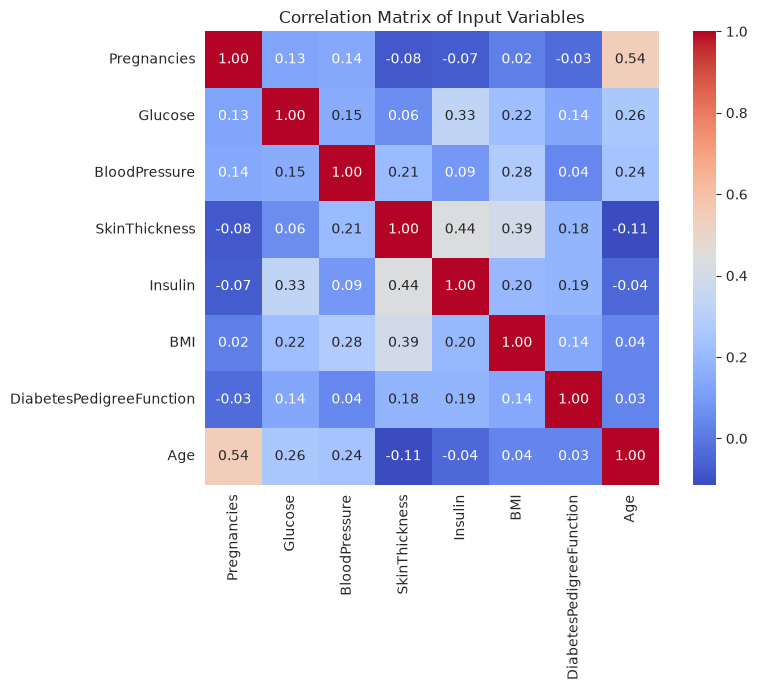

Strongest absolute correlations (excluding diagonal):
Pregnancies    Age              0.544
Age            Pregnancies      0.544
Insulin        SkinThickness    0.437
SkinThickness  Insulin          0.437
               BMI              0.393
BMI            SkinThickness    0.393
dtype: float64


In [2]:
# Correlation matrix
corr = df[COLS[:-1]].corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Matrix of Input Variables")
plt.tight_layout(); plt.savefig("images/fig1_corr.png", dpi=130, bbox_inches="tight"); plt.show()
print("Strongest absolute correlations (excluding diagonal):")
s = corr.abs().unstack().sort_values(ascending=False)
print(s[s < 1].head(6).round(3))

In [3]:
# Preprocessing: treat invalid zeros as missing, impute with median
dfc = df.copy()
zero_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
for c in zero_cols:
    dfc[c] = dfc[c].replace(0, np.nan)
print("Missing values after masking invalid zeros:")
print(dfc.isna().sum())
for c in zero_cols:
    dfc[c] = dfc[c].fillna(dfc[c].median())
print("\nAny missing left:", dfc.isna().sum().sum())

Missing values after masking invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Any missing left: 0


In [4]:
# Standardization and its effect on spread
from sklearn.preprocessing import StandardScaler
X = dfc[COLS[:-1]].values
Xs = StandardScaler().fit_transform(X)
print("Before scaling: mean=%.2f std=%.2f" % (X.mean(), X.std()))
print("After scaling:  mean=%.2f std=%.2f" % (Xs.mean(), Xs.std()))

Before scaling: mean=54.23 std=59.29
After scaling:  mean=0.00 std=1.00


In [5]:
# Euclidean / Manhattan / Cosine distances on raw vs standardized data
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances
sample = X[:3]; sample_s = Xs[:3]
for name, fn in [("Euclidean", euclidean_distances), ("Manhattan", manhattan_distances), ("Cosine", cosine_distances)]:
    print(f"--- {name} distances (raw) ---"); print(np.round(fn(sample), 3))
    print(f"--- {name} distances (standardized) ---"); print(np.round(fn(sample_s), 3))

--- Euclidean distances (raw) ---
[[ 0.    66.903 41.942]
 [66.903  0.    98.331]
 [41.942 98.331  0.   ]]
--- Euclidean distances (standardized) ---
[[0.    3.399 2.682]
 [3.399 0.    3.988]
 [2.682 3.988 0.   ]]
--- Manhattan distances (raw) ---
[[  0.    106.276  79.345]
 [106.276   0.    111.621]
 [ 79.345 111.621   0.   ]]
--- Manhattan distances (standardized) ---
[[0.    8.204 6.256]
 [8.204 0.    7.001]
 [6.256 7.001 0.   ]]
--- Cosine distances (raw) ---
[[0.    0.032 0.014]
 [0.032 0.    0.069]
 [0.014 0.069 0.   ]]
--- Cosine distances (standardized) ---
[[0.    1.585 0.562]
 [1.585 0.    1.405]
 [0.562 1.405 0.   ]]


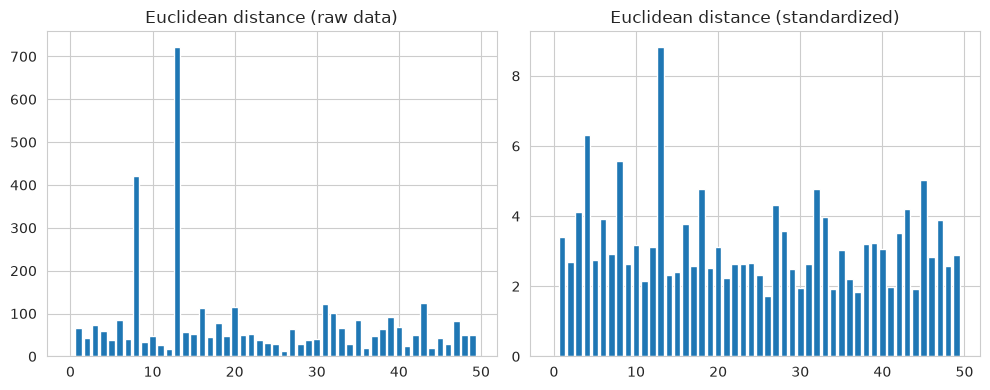

In [6]:
# Visual: distance from first observation before/after scaling
euc_raw = euclidean_distances(X[:50], X[:1]).ravel()
euc_std = euclidean_distances(Xs[:50], Xs[:1]).ravel()
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.bar(range(50), euc_raw); plt.title("Euclidean distance (raw data)")
plt.subplot(1,2,2); plt.bar(range(50), euc_std); plt.title("Euclidean distance (standardized)")
plt.tight_layout(); plt.savefig("images/fig2_distances.png", dpi=130, bbox_inches="tight"); plt.show()

## Key Observations
- Glucose and Outcome, BMI and Outcome are among the strongest correlations.
- Median imputation removed all invalid zeros without distorting distributions.
- Standardization makes distance measures meaningful by putting all features on one scale.